# Report 4 — XGBoost: giải thích và đánh giá (phần của duc)

Phần việc theo `docs/TEAM_HANDOVER_REPORT4.md` (mục 6, 7: bước 3c và 4):

1. So **bộ C** với **bộ C bỏ biến thời gian**: ΔPR-AUC từng fold, trung bình và khoảng dao động.
2. **Permutation importance** (tính trên validation của CV, không dùng tập test).
3. Kiểm tra phụ: train đợt 1 (25/09–05/10), test đợt 2 (10, 12, 19/10).
4. **Bảng so sánh 4 dòng** trên tập test (2 mốc, Logistic Regression, XGBoost) kèm confusion matrix.

**Trước khi chạy**
- `git pull` (hoặc chép đè `src/modeling/model.py` mới của phat), rồi **Restart kernel**.
- Đã chạy `uv sync --group xgboost`.
- Cần từ **phat**: `best_params` và `threshold` của XGBoost (kết quả `tune_xgb`), điền ở ô 2.
- Cần từ **BanNH** (chỉ cho bước 4): điểm dự đoán LR trên tập test và ngưỡng của LR.

Hàm của duc nằm trong `src/modeling/xgb_eval.py` (file riêng, không sửa `model.py`).

In [1]:
import sys, os
os.chdir(".."); sys.path.insert(0, os.getcwd())
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from src.modeling.split import doc_tap_sach, tach_train_test, loc_co_kha_nang, tom_tat
from src.modeling import model as M
from src.modeling import xgb_eval as E

pd.options.display.float_format = "{:.4f}".format

df = doc_tap_sach()
train, test = tach_train_test(df)               # toàn bộ is_clean
train, test = loc_co_kha_nang(train), loc_co_kha_nang(test)   # tập chính
tom_tat(train, test)   # phải khớp mục 5.1: train 8.152 / 315 trending, test 2.079 / 78

,tap,so_video,so_kenh,so_trending,ti_le_trending,pct_hanh_chinh
0,train,8152,1100,315,3.8600,29.2000
1,test,2079,291,78,3.7500,29.1000


## 1. Tham số đã chốt từ phat

Dán `best_params` và `threshold` do phat gửi (kết quả của `M.tune_xgb`). Không tự tinh chỉnh lại ở đây.

In [2]:
# Tham số phat đã chốt (xgb_best_params.json: bộ C, kiểu tree, random_state=42)
BEST_PARAMS = {"max_depth": 4, "learning_rate": 0.03, "n_estimators": 200,
               "min_child_weight": 5, "subsample": 0.8}
THRESHOLD_XGB = 0.7773813009262085   # ngưỡng F1 từ CV của phat
# PR-AUC CV của phat (để đối chiếu với kết quả của mình): 0.2398 ± 0.0826

assert BEST_PARAMS is not None and THRESHOLD_XGB is not None, "Điền tham số phat đã chốt trước khi chạy"
BEST_PARAMS, THRESHOLD_XGB

({'max_depth': 4,
  'learning_rate': 0.03,
  'n_estimators': 200,
  'min_child_weight': 5,
  'subsample': 0.8},
 0.7773813009262085)

## 2. Bộ C và bộ C bỏ biến thời gian (độ vững của kết luận LR)

Quy tắc đã chốt (mục 2): so PR-AUC của bộ C và bộ C bỏ các biến thời gian
(`time_slot`, `slot_detail`, `publish_hour_vn`, `publish_dow_vn`, `is_weekend`).
Hai lần chạy dùng **cùng fold, cùng tham số**, nên ΔPR-AUC = PR-AUC(C) − PR-AUC(C bỏ thời gian) so được từng fold.
ΔPR-AUC dương nghĩa là biến thời gian có giúp dự đoán.

In [3]:
r = E.so_sanh_co_bo_thoi_gian(train, BEST_PARAMS)
display(r["bang"])
pd.Series(r["tom_tat"])

,fold,pr_auc_C,pr_auc_C_bo_thoi_gian,delta
0,0,0.2689,0.2801,-0.0112
1,1,0.1445,0.1474,-0.0029
2,2,0.1573,0.1372,0.0201
3,3,0.3668,0.2756,0.0912
4,4,0.2275,0.2153,0.0122


pr_auc_C_tb                 0.2330
pr_auc_C_bo_thoi_gian_tb    0.2111
delta_tb                    0.0219
delta_std                   0.0406
delta_min                  -0.0112
delta_max                   0.0912
so_fold_delta_duong         3.0000
so_fold                     5.0000
so_cot_thoi_gian_bi_bo      5.0000
dtype: float64

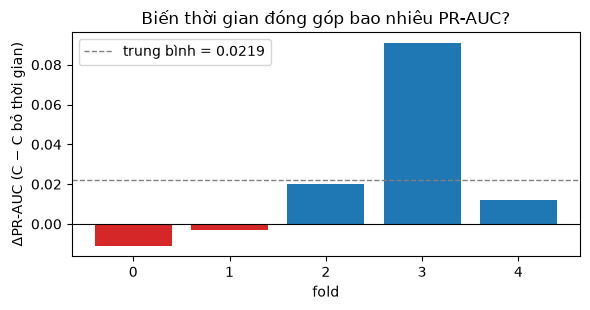

In [4]:
b = r["bang"]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(b["fold"].astype(str), b["delta"], color=["tab:blue" if d > 0 else "tab:red" for d in b["delta"]])
ax.axhline(0, color="black", lw=0.8)
ax.axhline(b["delta"].mean(), color="gray", ls="--", lw=1, label=f"trung bình = {b['delta'].mean():.4f}")
ax.set_xlabel("fold"); ax.set_ylabel("ΔPR-AUC (C − C bỏ thời gian)")
ax.set_title("Biến thời gian đóng góp bao nhiêu PR-AUC?"); ax.legend()
plt.tight_layout(); plt.show()

**Cách đọc (điền sau khi chạy):** ΔPR-AUC trung bình = …, dao động từ … đến … (… / 5 fold dương).
Mỗi fold chỉ có khoảng 60 video trending nên PR-AUC từng fold nhiễu; nếu khoảng dao động rộng hơn
hẳn giá trị trung bình thì không kết luận mạnh. So chiều với OR của LR (BanNH): cùng chiều → kết luận *vững*;
ngược chiều → ghi kết luận là *yếu* (mục 2).

## 3. Permutation importance

Hoán vị ngẫu nhiên từng cột trên **validation của từng fold** rồi đo PR-AUC giảm bao nhiêu (10 lần hoán vị mỗi cột).
Các cột thời gian tương quan với nhau, nên có thêm dòng **“NHÓM: thời gian”** hoán vị cả 5 cột cùng lúc;
số của từng cột thời gian lẻ có thể thấp giả vì cột kia gánh thay.

In [5]:
imp = E.permutation_importance_cv(train, BEST_PARAMS)
display(imp)

,feature,giam_pr_auc_tb,giam_pr_auc_std_fold,so_fold_giam_duong,so_fold
0,category_group,0.1411,0.0884,5,5
1,log10_duration,0.0758,0.0427,5,5
2,log10_subs,0.0719,0.0526,5,5
3,NHÓM: thời gian,0.0308,0.0245,5,5
4,publish_hour_vn,0.0286,0.0194,5,5
5,n_tags,0.0148,0.0278,4,5
6,release_date,0.0079,0.0113,4,5
7,is_live_or_premiere,0.0057,0.0047,4,5
8,title_length,0.0024,0.0219,3,5
9,publish_dow_vn,0.0019,0.0112,2,5


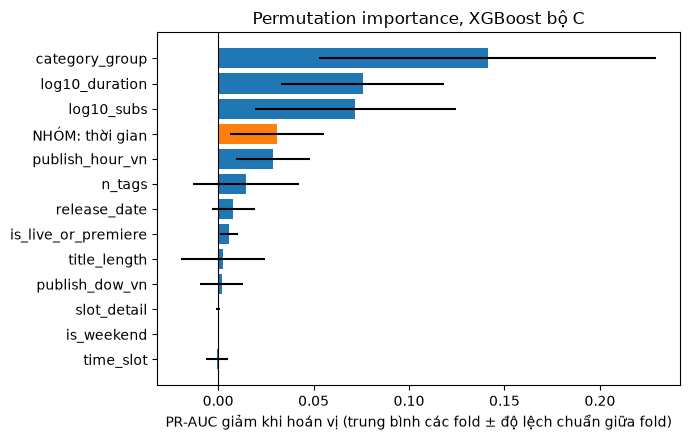

In [6]:
d = imp.sort_values("giam_pr_auc_tb")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(d["feature"], d["giam_pr_auc_tb"], xerr=d["giam_pr_auc_std_fold"],
        color=["tab:orange" if f.startswith("NHÓM") else "tab:blue" for f in d["feature"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("PR-AUC giảm khi hoán vị (trung bình các fold ± độ lệch chuẩn giữa fold)")
ax.set_title("Permutation importance, XGBoost bộ C")
plt.tight_layout(); plt.show()

## 4. Kiểm tra phụ: train đợt 1 → test đợt 2

Train: video đăng 25/09–05/10. Test: video đăng 10, 12, 19/10. Chỉ dùng **các kênh train**, không đụng vào kênh của tập test giữ riêng.
Ngưỡng chọn bằng CV trong đợt 1. Bỏ biến ngày đăng (`release_date`) vì ngày của đợt 2 chưa từng gặp lúc train.
Lưu ý: cùng một kênh có thể có video ở cả hai đợt, nên đây là kiểm tra ổn định theo thời gian, không phải theo kênh mới.

In [7]:
k = E.kiem_tra_dot(train, BEST_PARAMS)
display(k["thong_ke"])
display(k["bang_chi_so"][["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc",
                          "precision_top1pct", "precision_top5pct", "tn", "fp", "fn", "tp"]])
print("Ngưỡng (chọn bằng CV trong đợt 1):", round(k["threshold"], 4))

,dot,so_video,so_trending,ti_le_%
0,đợt 1 (train),6054,266,4.3900
1,đợt 2 (test),2098,49,2.3400


,accuracy,precision,recall,f1,pr_auc,roc_auc,precision_top1pct,precision_top5pct,tn,fp,fn,tp
XGBoost (train đợt 1 -> test đợt 2),0.9342,0.2013,0.6122,0.3030,0.2617,0.9124,0.3810,0.2286,1930.0000,119.0000,19.0000,30.0000
mốc: luôn đoán 0,0.9766,0.0000,0.0000,0.0000,0.0234,0.5000,0.0000,0.0190,2049.0000,0.0000,49.0000,0.0000
mốc: ngẫu nhiên theo tỉ lệ,0.9328,0.0208,0.0408,0.0276,0.0233,0.4975,0.0952,0.0190,1955.0000,94.0000,47.0000,2.0000


Ngưỡng (chọn bằng CV trong đợt 1): 0.6876


## 5. Bảng so sánh 4 dòng trên tập test

⚠️ **Chỉ chạy đúng một lần.** Hàm từ chối chạy nếu `da_chot=False`. Điểm LR lấy từ `lr_test_predictions.csv` của BanNH
(bộ C, ngưỡng 0,7484); `doc_diem_lr` khớp theo `video_id` và dừng nếu nhãn lệch với `test`.
Nếu file nằm chỗ khác, sửa đường dẫn ở ô dưới.

In [9]:
# Điểm LR của BanNH (bộ C), xếp theo video_id đúng thứ tự dòng của test; có kiểm tra nhãn y khớp
LR_SCORE, LR_THRESHOLD = E.doc_diem_lr(test, "data/processed/lr_test_predictions.csv")

# phat (XGBoost) và BanNH (LR) đã chốt -> đổi thành True và chạy ĐÚNG MỘT LẦN
DA_CHOT = True

bang, ma_tran = E.bang_so_sanh_test(train, test, BEST_PARAMS, THRESHOLD_XGB,
                                    lr_score=LR_SCORE, lr_threshold=LR_THRESHOLD, da_chot=DA_CHOT)
cot = ["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc", "precision_top1pct", "precision_top5pct"]
display(bang[cot])
display(bang[["tn", "fp", "fn", "tp"]])

,accuracy,precision,recall,f1,pr_auc,roc_auc,precision_top1pct,precision_top5pct
mốc: luôn đoán 0,0.9625,0.0000,0.0000,0.0000,0.0375,0.5000,0.0476,0.0288
mốc: ngẫu nhiên theo tỉ lệ,0.9211,0.0114,0.0128,0.0120,0.0372,0.4847,0.0000,0.0096
Logistic Regression,0.9168,0.1481,0.2564,0.1878,0.1538,0.8110,0.2381,0.1346
XGBoost,0.9485,0.2958,0.2692,0.2819,0.2279,0.8678,0.3810,0.2500


,tn,fp,fn,tp
mốc: luôn đoán 0,2001.0000,0.0000,78.0000,0.0000
mốc: ngẫu nhiên theo tỉ lệ,1914.0000,87.0000,77.0000,1.0000
Logistic Regression,1886.0000,115.0000,58.0000,20.0000
XGBoost,1951.0000,50.0000,57.0000,21.0000


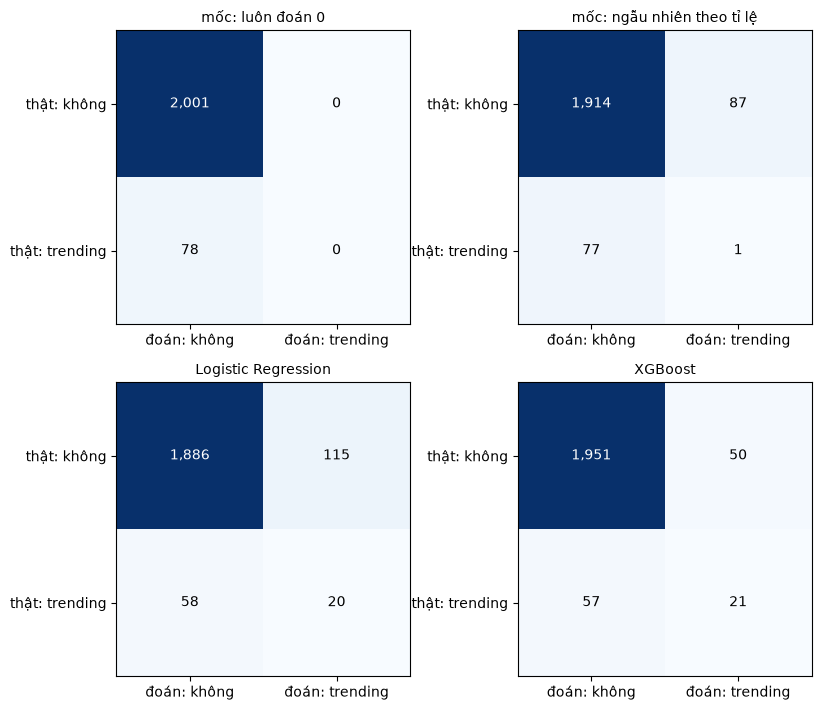

In [10]:
fig = E.ve_confusion(ma_tran)
plt.show()

**Đọc bảng:** chọn mô hình bằng **PR-AUC** (mục 5.5). Accuracy luôn đọc cạnh mô hình mốc “luôn đoán 0”
(đạt khoảng 96,2% trên tập chính), nên accuracy 96% không chứng tỏ mô hình tốt; nhìn recall, F1 và PR-AUC.

## 6. Nhận xét 

-Biến thời gian đóng góp rất ít vào dự đoán: ΔPR-AUC trung bình +0,022, dao động −0,011 đến +0,091, chỉ 3/5 fold dương và bị fold 3 chi phối.
-Theo permutation importance, các biến quan trọng nhất là thể loại, thời lượng và quy mô kênh. Nhóm thời gian đứng sau (0,031), chủ yếu nhờ giờ đăng -chi tiết; time_slot gần như không đóng góp.
-Trên tập test, XGBoost đạt PR-AUC 0,228 so với LR 0,154 và mốc 0,038. Recall tương đương (0,27 và 0,26), nhưng precision gấp đôi (0,30 và 0,15) nhờ -ít cảnh báo sai hơn (50 và 115).
-Kiểm tra đợt 1 → đợt 2 cho PR-AUC 0,262, nên mô hình ổn định theo thời gian.
-Giới hạn: test chỉ có 78 video trending nên các chỉ số nhiễu; dữ liệu quan sát nên chỉ nói “đi kèm”, không nói “gây ra”.